# Figure 8 — H2O–CO2 and saturation pressure


## 1. Imports and shared 00_Setup

This notebook is standalone, linear, and uses no custom Python functions. It keeps the original data selections and calculations while applying the current 00_Setup: Arial, full axes boxes, light gridlines where useful, 9-point bold uppercase panel labels, 300 dpi PNG export, and editable PDF/SVG text.


In [1]:
from pathlib import Path
import hashlib

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from PIL import Image

SINGLE_COLUMN_WIDTH_IN = 3.55
MAXIMUM_FIGURE_HEIGHT_IN = 7.8
FIGURE_WIDTH_IN = SINGLE_COLUMN_WIDTH_IN
FIGURE_HEIGHT_IN = 5.80
BASE_TEXT_SIZE_PT = 6.0
AXIS_LABEL_SIZE_PT = 7.0
TITLE_SIZE_PT = 7.5
TICK_LABEL_SIZE_PT = 6.0
LEGEND_SIZE_PT = 6.0
PANEL_LABEL_SIZE_PT = 9.0
EXPORT_DPI = 300
PUBLICATION_FONT = 'Arial'

installed_font_names = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in installed_font_names:
    raise RuntimeError('Arial is required by 00_Setup.')

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT,
    'axes.labelsize': AXIS_LABEL_SIZE_PT,
    'axes.titlesize': TITLE_SIZE_PT,
    'xtick.labelsize': TICK_LABEL_SIZE_PT,
    'ytick.labelsize': TICK_LABEL_SIZE_PT,
    'legend.fontsize': LEGEND_SIZE_PT,
    'legend.title_fontsize': LEGEND_SIZE_PT,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.linewidth': 0.5,
    'lines.linewidth': 0.75,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
    'savefig.dpi': EXPORT_DPI,
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
})


## 2. Paths and public S1–S3 workbooks

Set `DATA_DIRECTORY` to the folder containing the three public supplemental workbooks. The figure uses S1 data; S2 and S3 are checked as part of the shared package.


In [2]:
PROJECT_ROOT_OVERRIDE = None
PROJECT_ROOT = PROJECT_ROOT_OVERRIDE
if PROJECT_ROOT is None:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / 'SA_MI_Draft_FinalFigures_Work' / 'DataSheets').is_dir():
            PROJECT_ROOT = candidate
            break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the project or set PROJECT_ROOT_OVERRIDE.')
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
WORK_ROOT = PROJECT_ROOT / 'SA_MI_Draft_FinalFigures_Work'
DATA_DIRECTORY = WORK_ROOT / 'DataSheets' / 'Updated_Oct20'
FIGURE_DIRECTORY = WORK_ROOT / 'Nov6_AllFigures' / 'Figure_08_H2O_CO2_Saturation_Pressure'
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_08_H2O_CO2_Saturation_Pressure_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

S1_PATH = DATA_DIRECTORY / 'Dechert_S1_AllData.xlsx'
S2_PATH = DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx'
S3_PATH = DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx'
for workbook_path in [S1_PATH, S2_PATH, S3_PATH]:
    if not workbook_path.is_file():
        raise FileNotFoundError(f'Missing supplemental workbook: {workbook_path}')
SOURCE_HASHES_BEFORE = {
    'S1': hashlib.sha256(S1_PATH.read_bytes()).hexdigest(),
    'S2': hashlib.sha256(S2_PATH.read_bytes()).hexdigest(),
    'S3': hashlib.sha256(S3_PATH.read_bytes()).hexdigest(),
}
print('Data directory:', DATA_DIRECTORY)
print('Figure directory:', FIGURE_DIRECTORY)


Data directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20
Figure directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_08_H2O_CO2_Saturation_Pressure


## 3. Colors, markers, and source data


In [3]:
SAMPLE_COLORS = {'74D': '#F4A261', '74A': '#D55E00', '75': '#56B4E9', '76A': '#0072B2'}
SAMPLE_LABELS = {'74D': 'B Middle', '74A': 'B Base', '75': 'G Top', '76A': 'G Middle'}
PHASE_MARKERS = {'plag': 'o', 'pxy': 's'}
PHASE_LABELS = {'plag': 'Plagioclase-hosted MI', 'pxy': 'Pyroxene-hosted MI'}
MATRIX_MARKER = 'x'

h2o_col = 'H2O matrix wt% USE_SIMS'
h2o_err_col = 'H2O_1sigma_wt%_SIMS'
co2_col = 'Total_CO2_ppm_final'
co2_err_col = 'Total_CO2_ppm_error_1sigma_final'
pressure_col = 'P_bar_SatP'
sample_col = 'geologic_sample_SatP'
phase_col = 'Phase_SatP'
required_columns = ['base_name', 'mineral_phase', 'Discard_SIMS', h2o_col, h2o_err_col, co2_col, co2_err_col, pressure_col, sample_col, phase_col]

df_source = pd.read_excel(S1_PATH, sheet_name='MI_Hosts_Plag_Pxy', header=0)
missing_columns = [column for column in required_columns + ['Discard_SEMGlass_Raw'] if column not in df_source.columns]
if missing_columns:
    raise KeyError(f'Missing required MI_Hosts_Plag_Pxy columns: {missing_columns}')

sem_discarded = df_source['Discard_SEMGlass_Raw'].astype('string').str.strip().str.casefold().str.startswith('yes', na=False)
SEM_DISCARDED_IDS = set(df_source.loc[sem_discarded, 'base_name'])
df = df_source.loc[:, required_columns].copy()
df['sample_key'] = df['base_name'].astype('string').str.extract('^(74D|74A|75|76A)', expand=False)
df['is_matrix_glass'] = df['base_name'].astype('string').str.contains('MTX', case=False, na=False)
df['data_class'] = np.where(df['is_matrix_glass'], 'Matrix glass', 'Melt inclusion')
df['discard_sims_normalized'] = df['Discard_SIMS'].astype('string').str.strip().str.casefold()
df['discard_sims_yes'] = df['discard_sims_normalized'].eq('yes').fillna(False)
for column in [h2o_col, h2o_err_col, co2_col, co2_err_col, pressure_col]:
    df[column] = pd.to_numeric(df[column], errors='coerce')
df['finite_h2o_co2_pair'] = np.isfinite(df[h2o_col]) & np.isfinite(df[co2_col])
df['retained_panel_a'] = ~df['discard_sims_yes'] & df['finite_h2o_co2_pair']
panel_a = df.loc[df['retained_panel_a']].copy()

half_specs = [('74D', 'B', 'left'), ('74A', 'B', 'right'), ('75', 'G', 'left'), ('76A', 'G', 'right')]
pair_positions = {'B': 0.0, 'G': 1.35}
sat_pressure = df.loc[~df['base_name'].isin(SEM_DISCARDED_IDS), ['base_name', pressure_col, sample_col, phase_col]].copy()
sat_pressure[sample_col] = sat_pressure[sample_col].astype('string').str.strip()
sat_pressure[phase_col] = sat_pressure[phase_col].astype('string').str.strip().str.casefold()
sat_pressure = sat_pressure.loc[np.isfinite(sat_pressure[pressure_col]) & sat_pressure[sample_col].isin([spec[0] for spec in half_specs])].copy()
sat_pressure['Pressure_MPa_display'] = sat_pressure[pressure_col] / 10.0

print('Source rows:', len(df_source))
print('Panel A rows:', len(panel_a))
print('Stored saturation pressures:', len(sat_pressure))


Source rows: 212
Panel A rows: 119
Stored saturation pressures: 112


## 4. Audit tables


In [4]:
SOURCE_COUNTS_PATH = OUTPUT_DIRECTORY / 'Figure_08_H2O_CO2_Source_Counts.csv'
DISCARD_AUDIT_PATH = OUTPUT_DIRECTORY / 'Figure_08_H2O_CO2_SIMS_Discard_Audit.csv'
PRESSURE_COUNTS_PATH = OUTPUT_DIRECTORY / 'Figure_08_SaturationPressure_Counts.csv'
PRESSURE_MEDIANS_PATH = OUTPUT_DIRECTORY / 'Figure_08_SaturationPressure_Medians.csv'

source_count_rows = [
    {'section': 'source', 'sample_key': 'All', 'data_class': 'All', 'metric': 'MI_Hosts_Plag_Pxy source rows', 'count': len(df)},
    {'section': 'filter', 'sample_key': 'All', 'data_class': 'All', 'metric': 'Discard_SIMS = Yes rows', 'count': int(df['discard_sims_yes'].sum())},
    {'section': 'availability', 'sample_key': 'All', 'data_class': 'All', 'metric': 'finite H2O-total CO2 pairs before discard filter', 'count': int(df['finite_h2o_co2_pair'].sum())},
    {'section': 'panel_a', 'sample_key': 'All', 'data_class': 'All', 'metric': 'retained finite H2O-total CO2 pairs', 'count': len(panel_a)},
    {'section': 'panel_a', 'sample_key': 'All', 'data_class': 'All', 'metric': 'retained rows with H2O uncertainty', 'count': int(np.isfinite(panel_a[h2o_err_col]).sum())},
    {'section': 'panel_a', 'sample_key': 'All', 'data_class': 'All', 'metric': 'retained rows with total CO2 uncertainty', 'count': int(np.isfinite(panel_a[co2_err_col]).sum())},
]
for (sample_key, data_class), count in panel_a.groupby(['sample_key', 'data_class']).size().items():
    source_count_rows.append({'section': 'panel_a', 'sample_key': sample_key, 'data_class': data_class, 'metric': 'retained finite H2O-total CO2 pairs', 'count': int(count)})
source_counts = pd.DataFrame(source_count_rows)
discard_audit = df.loc[:, ['base_name', 'sample_key', 'data_class', 'Discard_SIMS', 'discard_sims_normalized', 'discard_sims_yes', 'finite_h2o_co2_pair', 'retained_panel_a']].copy()

pressure_count_rows = []
pressure_median_rows = []
for sample, pair, side in half_specs:
    subset = sat_pressure.loc[sat_pressure[sample_col].eq(sample)]
    phase_counts = subset[phase_col].value_counts()
    median_pressure = float(subset[pressure_col].median())
    pressure_count_rows.append({'sample_key': sample, 'sample_label': SAMPLE_LABELS[sample], 'pair': pair, 'side': side, 'stored_pressure_count': len(subset), 'plagioclase_count': int(phase_counts.get('plag', 0)), 'pyroxene_count': int(phase_counts.get('pxy', 0))})
    pressure_median_rows.append({'sample_key': sample, 'sample_label': SAMPLE_LABELS[sample], 'pair': pair, 'side': side, 'stored_pressure_count': len(subset), 'median_pressure_bar': median_pressure, 'median_depth_km': median_pressure / 264.87, 'minimum_pressure_bar': float(subset[pressure_col].min()), 'maximum_pressure_bar': float(subset[pressure_col].max())})
pressure_counts = pd.DataFrame(pressure_count_rows)
pressure_medians = pd.DataFrame(pressure_median_rows)
source_counts.to_csv(SOURCE_COUNTS_PATH, index=False)
discard_audit.to_csv(DISCARD_AUDIT_PATH, index=False)
pressure_counts.to_csv(PRESSURE_COUNTS_PATH, index=False)
pressure_medians.to_csv(PRESSURE_MEDIANS_PATH, index=False)


## 5. Plot and export


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_08_H2O_CO2_Saturation_Pressure/Figure_08_H2O_CO2_Saturation_Pressure_Final/Figure_08_H2O_CO2_Saturation_Pressure


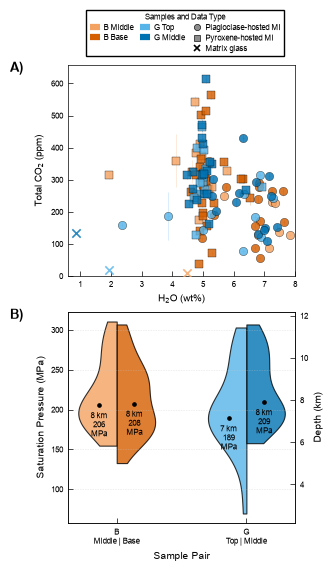

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN))
ax_a, ax_b = axes
fig.subplots_adjust(left=0.19, right=0.83, bottom=0.075, top=0.865, hspace=0.17)

matrix_rows = panel_a.loc[panel_a['data_class'].eq('Matrix glass')]
mi_rows = panel_a.loc[panel_a['data_class'].eq('Melt inclusion')]
for sample, color in SAMPLE_COLORS.items():
    matrix_subset = matrix_rows.loc[matrix_rows['sample_key'].eq(sample)]
    if not matrix_subset.empty:
        ax_a.scatter(matrix_subset[h2o_col], matrix_subset[co2_col], facecolor=color, marker=MATRIX_MARKER, s=36, linewidths=1.2, alpha=0.82, zorder=3)
    for phase, marker in PHASE_MARKERS.items():
        subset = mi_rows.loc[mi_rows['sample_key'].eq(sample) & mi_rows['mineral_phase'].eq(phase)]
        if subset.empty:
            continue
        ax_a.errorbar(subset[h2o_col], subset[co2_col], xerr=subset[h2o_err_col], yerr=subset[co2_err_col], fmt='none', ecolor=color, elinewidth=0.5, alpha=0.32, zorder=1)
        ax_a.scatter(subset[h2o_col], subset[co2_col], facecolor=color, marker=marker, s=36, alpha=0.82, edgecolors='black', linewidths=0.28, zorder=3)
ax_a.set_xlabel('H$_2$O (wt%)')
ax_a.set_ylabel('Total CO$_2$ (ppm)')
ax_a.set_xlim(0.6, 8.0)
ax_a.set_ylim(bottom=0)
ax_a.grid(False)

sample_handles = [Line2D([0, 1], [0, 0], color=SAMPLE_COLORS[sample], linewidth=4.5, solid_capstyle='butt', label=SAMPLE_LABELS[sample]) for sample in SAMPLE_COLORS]
phase_handles = [Line2D([0], [0], marker=PHASE_MARKERS[phase], linestyle='none', markerfacecolor='0.55', markeredgecolor='black', markeredgewidth=0.45, markersize=4.5, label=PHASE_LABELS[phase]) for phase in ['plag', 'pxy']]
phase_handles.append(Line2D([0], [0], marker=MATRIX_MARKER, linestyle='none', color='black', markeredgewidth=1.2, markersize=5.0, label='Matrix glass'))
blank_handle = Line2D([], [], linestyle='none', label=' ')
fig.legend(handles=[sample_handles[0], sample_handles[1], blank_handle, sample_handles[2], sample_handles[3], blank_handle, *phase_handles], title='Samples and Data Type', ncol=3, loc='upper center', bbox_to_anchor=(0.52, 0.960), frameon=True, framealpha=1.0, edgecolor='black', fancybox=False, borderaxespad=0, borderpad=0.4, labelspacing=0.25, handleheight=0.7, columnspacing=0.8, handlelength=1.2, handletextpad=0.45, fontsize=LEGEND_SIZE_PT, title_fontsize=LEGEND_SIZE_PT)
ax_a.text(-0.255, 1.015, 'A)', transform=ax_a.transAxes, fontsize=PANEL_LABEL_SIZE_PT, fontweight='bold', ha='left', va='top', clip_on=False)

median_plot_records = []
for sample, pair, side in half_specs:
    values = sat_pressure.loc[sat_pressure[sample_col].eq(sample), 'Pressure_MPa_display'].dropna()
    if values.empty:
        raise ValueError(f'No finite stored pressure values for {side} half at {pair}.')
    position = pair_positions[pair]
    parts = ax_b.violinplot(values, positions=[position], widths=0.8, showmeans=False, showmedians=False, showextrema=False)
    body = parts['bodies'][0]
    vertices = body.get_paths()[0].vertices
    if side == 'left':
        vertices[:, 0] = np.minimum(vertices[:, 0], position)
        median_x = position - 0.8 * 0.23
    else:
        vertices[:, 0] = np.maximum(vertices[:, 0], position)
        median_x = position + 0.8 * 0.23
    body.set_facecolor(SAMPLE_COLORS[sample])
    body.set_edgecolor('black')
    body.set_alpha(0.8)
    body.set_linewidth(0.8)
    median_pressure = float(values.median())
    median_depth = median_pressure / 26.487
    ax_b.scatter(median_x, median_pressure, color='black', marker='.', s=22, zorder=5)
    ax_b.text(median_x, median_pressure - 8, f'{median_depth:.0f} km\n{median_pressure:.0f}\nMPa', ha='center', va='top', fontsize=6.0, color='black', zorder=6)
    median_plot_records.append({'sample_key': sample, 'median_x': median_x, 'median_pressure_MPa': median_pressure, 'median_depth_km': median_depth})
ax_b.set_xticks([pair_positions['B'], pair_positions['G']])
ax_b.set_xticklabels(['B\nMiddle | Base', 'G\nTop | Middle'])
ax_b.set_xlabel('Sample Pair')
ax_b.set_ylabel('Saturation Pressure (MPa)')
pressure_span = sat_pressure['Pressure_MPa_display'].max() - sat_pressure['Pressure_MPa_display'].min()
ax_b.set_ylim(sat_pressure['Pressure_MPa_display'].min() - 0.05 * pressure_span, sat_pressure['Pressure_MPa_display'].max() + 0.05 * pressure_span)
ax_b.grid(True, axis='y', linestyle=':', linewidth=0.45, color='0.78', alpha=0.65)
ax_depth = ax_b.twinx()
pressure_limits = ax_b.get_ylim()
ax_depth.set_ylim(pressure_limits[0] / 26.487, pressure_limits[1] / 26.487)
ax_depth.set_ylabel('Depth (km)')
ax_depth.grid(False)
ax_a.text(-0.255, 1.015, 'B)', transform=ax_b.transAxes, fontsize=PANEL_LABEL_SIZE_PT, fontweight='bold', ha='left', va='top', clip_on=False)
for axis in [ax_a, ax_b, ax_depth]:
    for spine in axis.spines.values():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(0.5)

OUTPUT_STEM = OUTPUT_DIRECTORY / 'Figure_08_H2O_CO2_Saturation_Pressure'
fig.savefig(OUTPUT_STEM.with_suffix('.pdf'), format='pdf', facecolor='white')
fig.savefig(OUTPUT_STEM.with_suffix('.svg'), format='svg', facecolor='white')
fig.savefig(OUTPUT_STEM.with_suffix('.png'), format='png', dpi=EXPORT_DPI, facecolor='white')
print('Saved:', OUTPUT_STEM)
plt.show()


In [6]:
expected_exports = [OUTPUT_STEM.with_suffix(suffix) for suffix in ['.pdf', '.png', '.svg']]
assert len(axes) == 2
assert int(df['discard_sims_yes'].sum()) == 13
assert not panel_a['discard_sims_yes'].any()
assert panel_a[[h2o_col, co2_col]].notna().all().all()
assert np.isfinite(panel_a[[h2o_col, co2_col]].to_numpy()).all()
assert len(panel_a) == 119
assert int(panel_a['data_class'].eq('Melt inclusion').sum()) == 116
assert int(panel_a['data_class'].eq('Matrix glass').sum()) == 3
assert int(np.isfinite(panel_a[h2o_err_col]).sum()) == 119
assert int(np.isfinite(panel_a[co2_err_col]).sum()) == 119
assert len(sat_pressure) == 112
assert not sat_pressure['base_name'].astype('string').str.contains('MTX', case=False, na=False).any()
assert pressure_counts.set_index('sample_key')['stored_pressure_count'].to_dict() == {'74D': 22, '74A': 36, '75': 23, '76A': 31}
assert pressure_medians.set_index('sample_key')['median_pressure_bar'].to_dict() == {'74D': 2056.0, '74A': 2075.0, '75': 1891.0, '76A': 2094.0}
assert ax_a.get_xlabel() == 'H$_2$O (wt%)'
assert ax_a.get_ylabel() == 'Total CO$_2$ (ppm)'
assert ax_b.get_xlabel() == 'Sample Pair'
assert ax_b.get_ylabel() == 'Saturation Pressure (MPa)'
assert ax_depth.get_ylabel() == 'Depth (km)'
assert [label.get_text() for label in ax_b.get_xticklabels()] == ['B\nMiddle | Base', 'G\nTop | Middle']
assert len(median_plot_records) == 4
assert all(path.is_file() and path.stat().st_size > 0 for path in expected_exports)
with Image.open(OUTPUT_STEM.with_suffix('.png')) as image:
    assert image.size == (round(FIGURE_WIDTH_IN * EXPORT_DPI), round(FIGURE_HEIGHT_IN * EXPORT_DPI))
svg_text = OUTPUT_STEM.with_suffix('.svg').read_text(encoding='utf-8')
assert '<text' in svg_text and '<image' not in svg_text.casefold()
assert b'/Type3' not in OUTPUT_STEM.with_suffix('.pdf').read_bytes()
assert {k: hashlib.sha256(p.read_bytes()).hexdigest() for k, p in {'S1': S1_PATH, 'S2': S2_PATH, 'S3': S3_PATH}.items()} == SOURCE_HASHES_BEFORE
print('Figure 8 validation passed.')
print('No custom functions; source workbooks unchanged; PDF/SVG remain editable vector exports.')


Figure 8 validation passed.
No custom functions; source workbooks unchanged; PDF/SVG remain editable vector exports.
